# 17 · Three loss families on one task: regression, classification, denoising

In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

N_BINS, T_DIFF = 64, 50
BINS = torch.linspace(-2, 2, N_BINS + 1)
CENTERS = (BINS[:-1] + BINS[1:]) / 2
betas = torch.linspace(1e-4, 0.2, T_DIFF)
alphas_bar = torch.cumprod(1 - betas, 0)

def demos(n, seed=0):
    g = torch.Generator().manual_seed(seed)
    obs = torch.rand(n, 1, generator=g) * 2 - 1
    side = torch.where(torch.rand(n, 1, generator=g) < 0.5, -1.0, 1.0)
    act = side * (0.6 + 0.4 * obs.abs()) + 0.05 * torch.randn(n, 1, generator=g)
    return obs, act

def mlp(d_in, d_out):
    return nn.Sequential(nn.Linear(d_in, 128), nn.SiLU(), nn.Linear(128, 128), nn.SiLU(), nn.Linear(128, d_out))

def fit(model, loss_fn, steps=4000):
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    log = []
    for _ in range(steps):
        obs, act = demos(256, seed=np.random.randint(1 << 30))
        loss = loss_fn(model, obs, act)
        opt.zero_grad(); loss.backward(); opt.step(); log.append(loss.item())
    return np.array(log)

def mse_loss(m, obs, act):
    return ((m(obs) - act) ** 2).mean()

def ce_loss(m, obs, act):
    target = torch.clamp(torch.bucketize(act[:, 0], BINS) - 1, 0, N_BINS - 1)
    return nn.functional.cross_entropy(m(obs), target)

def denoise_loss(m, obs, act):
    t = torch.randint(0, T_DIFF, (len(act),))
    eps = torch.randn_like(act)
    ab = alphas_bar[t][:, None]
    noisy = ab.sqrt() * act + (1 - ab).sqrt() * eps
    return ((m(torch.cat([noisy, obs, t[:, None] / T_DIFF], 1)) - eps) ** 2).mean()

@torch.no_grad()
def sample_diffusion(m, obs):
    x = torch.randn(len(obs), 1)
    for t in reversed(range(T_DIFF)):
        eps = m(torch.cat([x, obs, torch.full((len(obs), 1), t / T_DIFF)], 1))
        a, ab = 1 - betas[t], alphas_bar[t]
        x = (x - (1 - a) / (1 - ab).sqrt() * eps) / a.sqrt()
        if t > 0:
            x += betas[t].sqrt() * torch.randn_like(x)
    return x

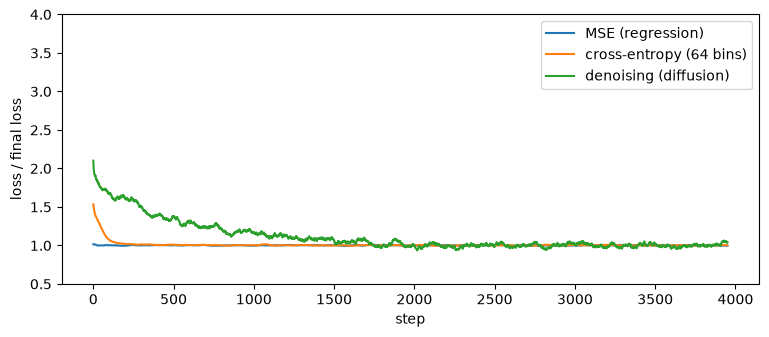

In [2]:
torch.manual_seed(0); np.random.seed(0)
models = {"MSE (regression)": mlp(1, 1), "cross-entropy (64 bins)": mlp(1, N_BINS), "denoising (diffusion)": mlp(3, 1)}
losses = {name: fit(m, fn) for (name, m), fn in zip(models.items(), [mse_loss, ce_loss, denoise_loss])}
plt.figure(figsize=(9, 3.5))
for name, l in losses.items():
    plt.plot(np.convolve(l, np.ones(50) / 50, "valid") / l[-500:].mean(), label=name)
plt.ylim(0.5, 4); plt.ylabel("loss / final loss"); plt.xlabel("step"); plt.legend(); plt.show()

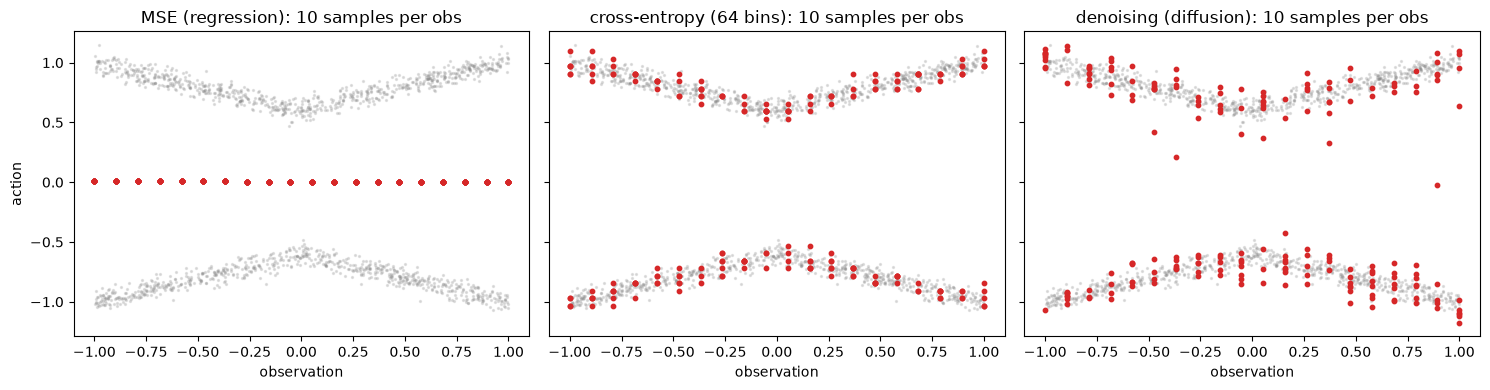

In [3]:
obs_test = torch.linspace(-1, 1, 20)[:, None].repeat_interleave(10, 0)
with torch.no_grad():
    s_mse = models["MSE (regression)"](obs_test)
    p = torch.softmax(models["cross-entropy (64 bins)"](obs_test), -1)
    s_ce = CENTERS[torch.multinomial(p, 1)[:, 0]][:, None]
s_diff = sample_diffusion(models["denoising (diffusion)"], obs_test)
o, a = demos(1500, seed=123)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, s) in zip(axes, {"MSE (regression)": s_mse, "cross-entropy (64 bins)": s_ce, "denoising (diffusion)": s_diff}.items()):
    ax.scatter(o, a, s=2, alpha=0.2, c="gray"); ax.scatter(obs_test, s, s=10, c="tab:red")
    ax.set_title(f"{name}: 10 samples per obs"); ax.set_xlabel("observation")
axes[0].set_ylabel("action"); plt.tight_layout(); plt.show()